# Employee Dataset - Exploratory Data Analysis & Visualization Notebook

This notebook demonstrates end-to-end Exploratory Data Analysis (EDA) on an employee dataset (`sample.csv`), covering data loading, structural inspection, column selection/dropping, groupby aggregations, and Matplotlib visualizations.

### 1. Import Data Science Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### 2. Load Dataset (`sample.csv`)

In [2]:
# Load sample employee CSV dataset into Pandas DataFrame
data = pd.read_csv('sample.csv')
df = pd.DataFrame(data)
df.head()

,Id,first_name,last_name,age,job,location
0,4000001,Kristina,Chung,55,Pilot,india
1,4000002,Paige,Chen,74,Teacher,uk
2,4000003,Sherri,Melton,34,Firefighter,us
3,4000004,Gretchen,Hill,66,Computer hardware engineer,china
4,4000005,Karen,Puckett,74,Lawyer,africa


### 3. Subset Column Selection

In [3]:
# Extract specific columns: first_name, age, location
df_2 = df[['first_name', 'age', 'location']]
df_2.head()

,first_name,age,location
0,Kristina,55,india
1,Paige,74,uk
2,Sherri,34,us
3,Gretchen,66,china
4,Karen,74,africa


### 4. Data Inspection & Summary Statistics

#### 4.1 Statistical Summary (`df.describe()`)

In [4]:
# Generate summary statistics (mean, std, min, quartiles, max)
df.describe()

,Id,age
count,4.630000e+02,463.000000
mean,4.000232e+06,49.673866
std,1.338008e+02,15.606897
min,4.000001e+06,21.000000
25%,4.000116e+06,36.000000
50%,4.000232e+06,51.000000
75%,4.000348e+06,64.000000
max,4.000463e+06,75.000000


#### 4.2 Overall DataFrame Information (`df.info()`)

In [5]:
# Display column names, non-null counts, data types, and memory usage
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 463 entries, 0 to 462
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Id          463 non-null    int64
 1   first_name  463 non-null    str  
 2   last_name   463 non-null    str  
 3   age         463 non-null    int64
 4   job         463 non-null    str  
 5   location    462 non-null    str  
dtypes: int64(2), str(4)
memory usage: 35.4 KB


### 5. Column Manipulation

#### 5.1 Dropping Columns (`df.drop`)

In [6]:
# Drop 'age' column temporarily (use inplace=True to modify original DataFrame)
df.drop(columns=['age']).head()

,Id,first_name,last_name,job,location
0,4000001,Kristina,Chung,Pilot,india
1,4000002,Paige,Chen,Teacher,uk
2,4000003,Sherri,Melton,Firefighter,us
3,4000004,Gretchen,Hill,Computer hardware engineer,china
4,4000005,Karen,Puckett,Lawyer,africa


### 6. Groupby Aggregations & Analytical Queries

#### 6.1 Average Age per Job Role

In [7]:
# Compute mean age for each job title, sorted descending
df.groupby('job')['age'].mean().sort_values(ascending=False)

job
Computer software engineer         58.142857
Actor                              58.000000
africa                             58.000000
Social worker                      55.900000
Civil engineer                     55.727273
Photographer                       55.400000
Accountant                         54.888889
Financial analyst                  53.500000
Computer hardware engineer         52.857143
Therapist                          52.500000
Farmer                             52.125000
Chemist                            51.833333
Pilot                              51.615385
Engineering technician             51.555556
Doctor                             51.538462
Childcare worker                   51.411765
Pharmacist                         51.250000
Athlete                            51.222222
Dancer                             50.555556
Artist                             50.500000
Electrical engineer                50.363636
Psychologist                       50.200000
Secret

#### 6.2 Average Age by Job & Location

In [8]:
# Compute mean age grouped by job and location
df.groupby(['job', 'location'])['age'].mean().sort_values(ascending=False)

job                         location
Social worker               us          75.0
                            africa      74.0
Secretary                   china       74.0
Lawyer                      africa      74.0
Dancer                      africa      74.0
                                        ... 
Physicist                   us          24.0
Computer hardware engineer  africa      23.0
Reporter                    uk          23.0
Electrician                 china       22.0
Computer hardware engineer  ireland     22.0
Name: age, Length: 237, dtype: float64

#### 6.3 Multiple Aggregations: Max and Mean Age per Job

In [9]:
# Aggregate both maximum and average age for each job role
df.groupby('job')['age'].agg(['max', 'mean'])

,max,mean
job,,
Accountant,64,54.888889
Actor,73,58.000000
Agricultural and food scientist,70,46.222222
Architect,66,44.500000
Artist,75,50.500000
Athlete,69,51.222222
Automotive mechanic,70,47.000000
Carpenter,66,49.700000
Chemist,70,51.833333


### 7. Data Visualization using Matplotlib

#### 7.1 Bar Chart: Country-wise Average Age

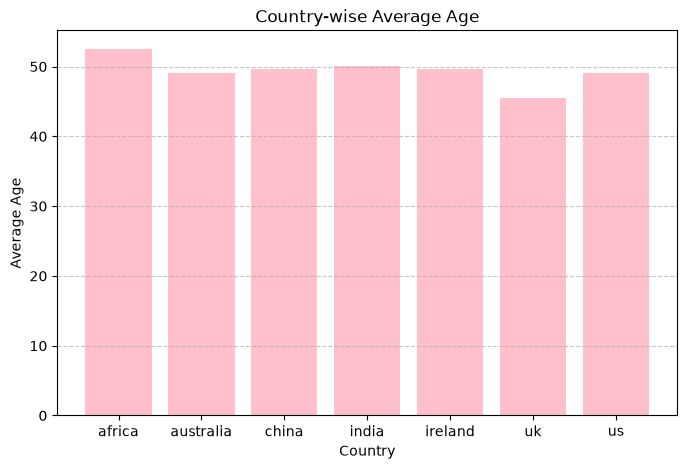

In [24]:
# Calculate country-wise average age
result = df.groupby('location')['age'].mean()

# Plot Bar Chart
plt.figure(figsize=(8, 5))
plt.bar(result.index, result.values, color='pink')
plt.title('Country-wise Average Age')
plt.xlabel('Country')
plt.ylabel('Average Age')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

#### 7.2 Bar Chart: Total People Count per Country

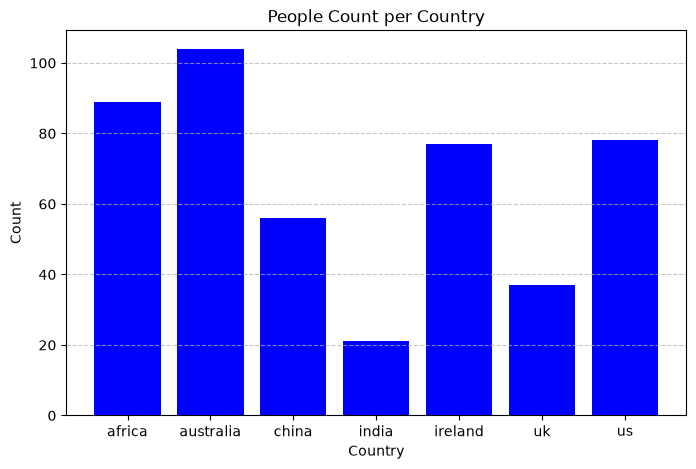

In [11]:
# Count number of employees per location
result = df.groupby('location')['Id'].count()

# Plot Bar Chart
plt.figure(figsize=(8, 5))
plt.bar(result.index, result.values, color='b')
plt.title('People Count per Country')
plt.xlabel('Country')
plt.ylabel('Count')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

#### 7.3 Bar Chart: Top 10 Job Titles by Employee Count

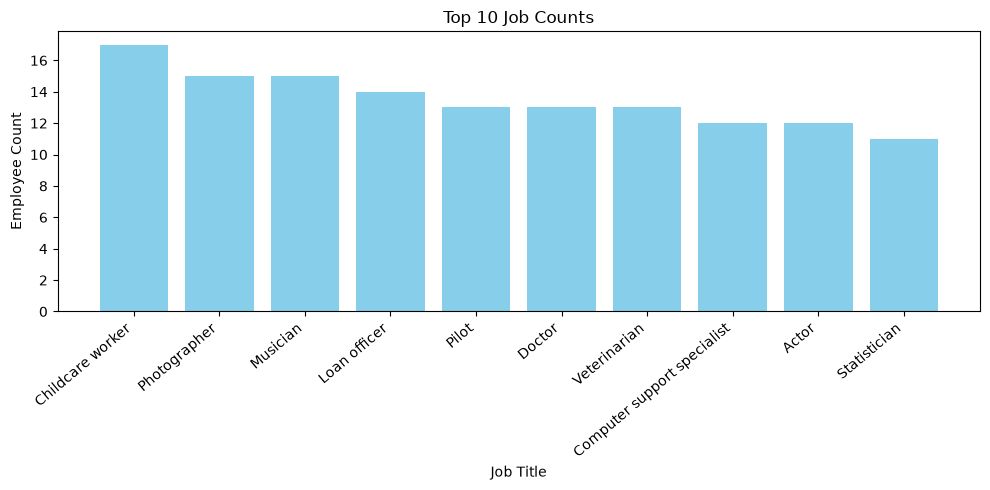

In [12]:
# Top 10 most common jobs
result = df.groupby('job')['Id'].count().sort_values(ascending=False).head(10)

# Plot Bar Chart with rotated X-axis ticks
plt.figure(figsize=(10, 5))
plt.bar(result.index, result.values, color='skyblue')
plt.xticks(rotation=40, ha='right')
plt.title('Top 10 Job Counts')
plt.xlabel('Job Title')
plt.ylabel('Employee Count')
plt.tight_layout()
plt.show()

#### 7.4 Bar Chart: Maximum Age per Location

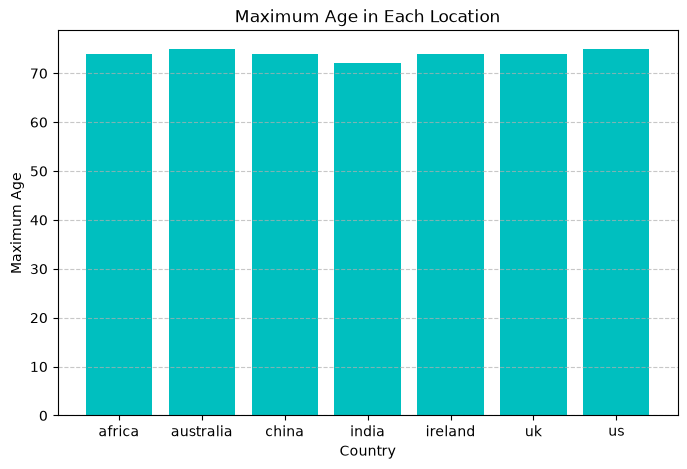

In [13]:
# Max age per country
result = df.groupby('location')['age'].max()

# Plot Bar Chart
plt.figure(figsize=(8, 5))
plt.bar(result.index, result.values, color='c')
plt.xlabel('Country')
plt.ylabel('Maximum Age')
plt.title('Maximum Age in Each Location')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

#### 7.5 Histogram: Age Distribution

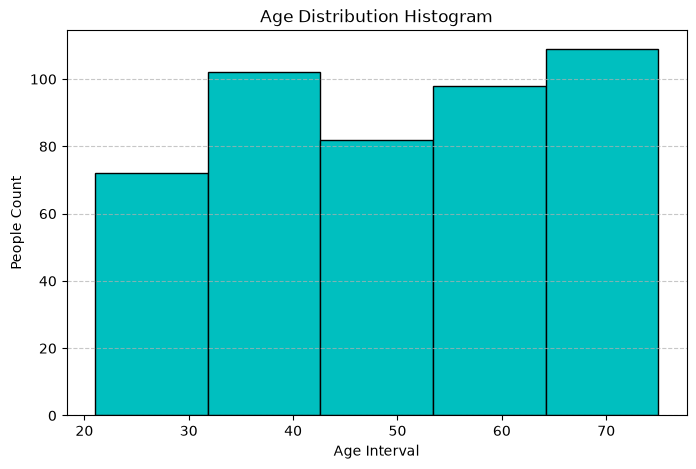

In [14]:
# Histogram to display distribution of numerical age across intervals
plt.figure(figsize=(8, 5))
plt.hist(df['age'].dropna(), bins=5, color='c', edgecolor='black')
plt.xlabel('Age Interval')
plt.ylabel('People Count')
plt.title('Age Distribution Histogram')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

#### 7.6 Pie Chart: Employee Share per Location

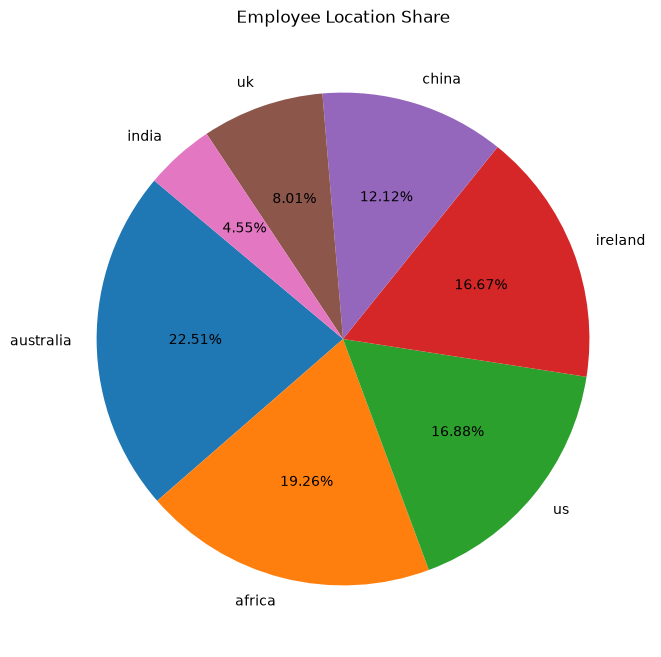

In [15]:
# Location proportions
result = df['location'].value_counts()

# Plot Pie Chart with percentage labels
plt.figure(figsize=(8, 8))
plt.pie(result.values, labels=result.index, autopct='%1.2f%%', startangle=140)
plt.title('Employee Location Share')
plt.show()

#### 7.7 Vertical & Horizontal Bar Charts: Min, Max, Avg Age Comparison

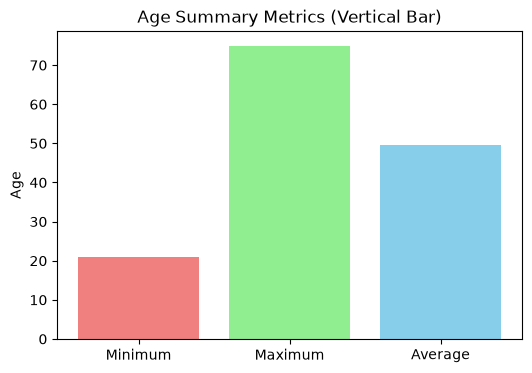

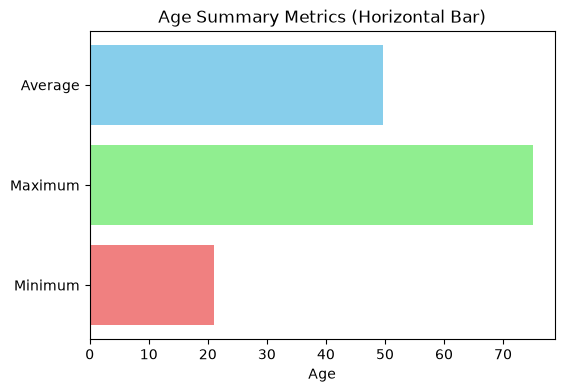

In [16]:
# Compute metrics
minimum = df['age'].min()
maximum = df['age'].max()
average = df['age'].mean()

values = [minimum, maximum, average]
labels = ['Minimum', 'Maximum', 'Average']

# Vertical Bar Chart
plt.figure(figsize=(6, 4))
plt.bar(labels, values, color=['lightcoral', 'lightgreen', 'skyblue'])
plt.ylabel('Age')
plt.title('Age Summary Metrics (Vertical Bar)')
plt.show()

# Horizontal Bar Chart (barh)
plt.figure(figsize=(6, 4))
plt.barh(labels, values, color=['lightcoral', 'lightgreen', 'skyblue'])
plt.xlabel('Age')
plt.title('Age Summary Metrics (Horizontal Bar)')
plt.show()